# Swaption surface forecasting: MLP vs variational quantum circuit

Goal: predict the next observation of a swaption surface (224 points) from its history.

Each surface is compressed to 4 PCA components. The models predict the change of these 4 coordinates from one date to the next, then I rebuild the full surface and measure the error in the original units. Three models are compared:
- a small MLP,
- a variational quantum circuit (4 qubits, simulated with Qiskit),
- persistence: the next surface is the current one.

Chronological 70/10/20 split (train/validation/test). The scaler and the PCA are fitted on the train set only, and the MLP and the circuit use the same training pairs.

## 1. Setup

In [20]:
#%pip install scikit-learn scipy qiskit openpyxl torch

In [21]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.optimize import minimize

seed = 123
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Classical MLP device:", device)

Classical MLP device: cuda


## 2. Load and inspect the data

`train_augmented.xlsx`: 5000 dates, 224 columns (one per tenor/maturity pair). Source of the data: Quandela.

In [22]:
data_path = "train_augmented.xlsx"

raw = pd.read_excel(data_path)
date_col = raw.columns[0]
raw[date_col] = pd.to_datetime(raw[date_col], dayfirst=True)

data = raw.sort_values(date_col).set_index(date_col)
assert not data.isna().any().any(), "missing values in the data"

print("Data shape (dates, surface points):", data.shape)
print("Date range:", data.index.min().date(), "to", data.index.max().date())
data.head()

Data shape (dates, surface points): (5000, 224)
Date range: 2031-12-14 to 2051-12-23


,Tenor : 1; Maturity : 0.0833333333333333,Tenor : 2; Maturity : 0.0833333333333333,Tenor : 3; Maturity : 0.0833333333333333,Tenor : 4; Maturity : 0.0833333333333333,Tenor : 5; Maturity : 0.0833333333333333,Tenor : 6; Maturity : 0.0833333333333333,Tenor : 7; Maturity : 0.0833333333333333,Tenor : 8; Maturity : 0.0833333333333333,Tenor : 9; Maturity : 0.0833333333333333,Tenor : 10; Maturity : 0.0833333333333333,...,Tenor : 5; Maturity : 30,Tenor : 6; Maturity : 30,Tenor : 7; Maturity : 30,Tenor : 8; Maturity : 30,Tenor : 9; Maturity : 30,Tenor : 10; Maturity : 30,Tenor : 15; Maturity : 30,Tenor : 20; Maturity : 30,Tenor : 25; Maturity : 30,Tenor : 30; Maturity : 30
Date,,,,,,,,,,,,,,,,,,,,,
2031-12-14,0.027625,0.036640,0.038249,0.039148,0.039088,0.037973,0.036945,0.036416,0.036497,0.035685,...,0.350524,0.348925,0.351395,0.345139,0.346616,0.343302,0.366879,0.380353,0.361199,0.348777
2031-12-16,0.028610,0.037731,0.039232,0.039957,0.039729,0.038461,0.037253,0.036641,0.036654,0.035771,...,0.351299,0.349653,0.351976,0.345653,0.346911,0.343366,0.367410,0.381059,0.362433,0.349960
2031-12-17,0.028745,0.037891,0.039316,0.039961,0.039691,0.038334,0.037041,0.036367,0.036336,0.035404,...,0.343776,0.342059,0.344360,0.338096,0.339422,0.336055,0.359613,0.372565,0.356301,0.345036
2031-12-19,0.028245,0.036961,0.038555,0.039461,0.039374,0.038220,0.037154,0.036591,0.036653,0.035808,...,0.350691,0.349102,0.351561,0.345349,0.346828,0.343537,0.366902,0.380087,0.361261,0.348834
2031-12-20,0.027030,0.035902,0.037512,0.038421,0.038382,0.037275,0.036248,0.035694,0.035766,0.034950,...,0.346054,0.344398,0.346783,0.340556,0.341993,0.338698,0.362000,0.375090,0.357312,0.345751


## 3. Chronological train/validation/test split

Dates are never shuffled across splits. The validation set is used for model selection and early stopping; the test set is reserved for final evaluation.

In [23]:
n = len(data)
train_end = int(0.70 * n)
val_end = int(0.80 * n)

train_df = data.iloc[:train_end].copy()
val_df = data.iloc[train_end:val_end].copy()
test_df = data.iloc[val_end:].copy()

print(f"Train      : {len(train_df):4d} rows | {train_df.index.min().date()} to {train_df.index.max().date()}")
print(f"Validation : {len(val_df):4d} rows | {val_df.index.min().date()} to {val_df.index.max().date()}")
print(f"Test       : {len(test_df):4d} rows | {test_df.index.min().date()} to {test_df.index.max().date()}")

Train      : 3500 rows | 2031-12-14 to 2045-12-19
Validation :  500 rows | 2045-12-21 to 2047-12-21
Test       : 1000 rows | 2047-12-22 to 2051-12-23


## 4. Standardization and PCA

The surface scaler and PCA are fitted on the training period only. I keep 4 components, one per qubit. They explain 99.97% of the variance.

In [24]:
n_components = 4

surface_scaler = StandardScaler()
train_scaled = surface_scaler.fit_transform(train_df)
val_scaled = surface_scaler.transform(val_df)
test_scaled = surface_scaler.transform(test_df)

pca = PCA(n_components=n_components, random_state=seed)
train_z = pca.fit_transform(train_scaled)
val_z = pca.transform(val_scaled)
test_z = pca.transform(test_scaled)

explained_variance = pca.explained_variance_ratio_.sum()
print("Number of PCA components:", n_components)
print(f"Explained variance: {explained_variance:.6%}")

Number of PCA components: 4
Explained variance: 99.972329%


## 5. Build one-day-ahead prediction pairs

For each date, the model receives the current PCA coordinates and predicts the change to the next date:

$$
\Delta z_{t+1} = z_{t+1} - z_t.
$$

For validation and test, the last point of the previous split is used as the first input, so that every date of the split gets a prediction.

In [25]:
def make_pairs(current_z, previous_z=None):
    """Create current-state inputs and next-day PCA changes."""
    if previous_z is None:
        z_all = current_z
    else:
        z_all = np.vstack([previous_z[-1:], current_z])

    X = z_all[:-1]
    y = z_all[1:] - z_all[:-1]
    return X.astype(float), y.astype(float)

X_train, y_train = make_pairs(train_z)
X_val, y_val = make_pairs(val_z, train_z)
X_test, y_test = make_pairs(test_z, val_z)

print("Training pairs  :", X_train.shape, y_train.shape)
print("Validation pairs:", X_val.shape, y_val.shape)
print("Test pairs      :", X_test.shape, y_test.shape)

Training pairs  : (3499, 4) (3499, 4)
Validation pairs: (500, 4) (500, 4)
Test pairs      : (1000, 4) (1000, 4)


## 6. Scale model inputs and targets

All scaling parameters are learned from training data only. The target changes are scaled by their training-set maximum absolute value, keeping the training targets in \([-1, 1]\). This is compatible with the bounded Pauli-Z expectation values returned by the quantum circuit.

The circuit is slow to simulate, so both models are trained on the same random subset of 500 training pairs (out of 3499).

In [26]:
x_scaler = StandardScaler().fit(X_train)
X_train_s = x_scaler.transform(X_train)
X_val_s = x_scaler.transform(X_val)
X_test_s = x_scaler.transform(X_test)

y_scale = np.max(np.abs(y_train), axis=0)
y_scale = np.where(y_scale < 1e-12, 1.0, y_scale)

y_train_s = y_train / y_scale
y_val_s = y_val / y_scale
y_test_s = y_test / y_scale

train_subsample = min(500, len(X_train_s))

rng_subset = np.random.default_rng(seed)
train_indices = np.sort(
    rng_subset.choice(len(X_train_s), size=train_subsample, replace=False)
)
X_fit_s = X_train_s[train_indices]
y_fit_s = y_train_s[train_indices]

## 7. Build the variational quantum circuit

The circuit has 4 qubits, one per PCA component. The inputs are encoded with RY/RZ rotations, then 3 layers of trainable RY/RZ rotations and CX gates follow. The outputs are the ⟨Z⟩ values of the qubits. The circuit is simulated on a classical machine, so no speed-up is expected.

In [27]:
n_qubits = n_components
n_layers = 3

reupload = False   # encode the inputs again at every layer

n_params = n_layers * n_qubits * 2

def encode(qc, x):
    for q in range(n_qubits):
        qc.ry(float(np.pi * np.tanh(x[q])), q)
        qc.rz(float(0.5 * np.pi * np.tanh(x[q])), q)

def build_circuit(x, theta):
    qc = QuantumCircuit(n_qubits)

    if not reupload:
        encode(qc, x)

    k = 0
    for _ in range(n_layers):
        if reupload:
            encode(qc, x)

        for q in range(n_qubits):
            qc.ry(float(theta[k]), q)
            k += 1
            qc.rz(float(theta[k]), q)
            k += 1

        # entanglement: a chain of CX, plus one gate to close the ring
        for q in range(n_qubits - 1):
            qc.cx(q, q + 1)
        if n_qubits > 2:
            qc.cx(n_qubits - 1, 0)

    return qc

def quantum_predict_one(x, theta):
    state = Statevector.from_instruction(build_circuit(x, theta[:n_params]))
    probabilities = state.probabilities()

    # <Z> on each qubit (Qiskit is little-endian: qubit q is bit q of the index)
    outputs = []
    for q in range(n_qubits):
        expectation_z = 0.0
        for basis, p in enumerate(probabilities):
            bit = (basis >> q) & 1
            expectation_z += p if bit == 0 else -p
        outputs.append(expectation_z)
    outputs = np.array(outputs)

    return outputs

def quantum_predict(X, theta):
    return np.vstack([quantum_predict_one(x, theta) for x in X])

example_theta = np.zeros(n_params)
print("Qubits:", n_qubits)
print("Trainable parameters:", n_params)
print("Circuit depth (example):", build_circuit(X_fit_s[0], example_theta).depth())

Qubits: 4
Trainable parameters: 24
Circuit depth (example): 20


## 8. Train the quantum model

COBYLA minimizes the MSE on the training pairs. Each evaluation simulates the circuit for all of them, so I limit it to 200 evaluations (in COBYLA, `maxiter` counts function evaluations, not iterations). The validation MSE is only tracked, and the test set is never used here.

Iteration   1 | Train MSE: 0.274102 | Val MSE: 0.259431
Iteration   2 | Train MSE: 0.207874 | Val MSE: 0.197468
Iteration   3 | Train MSE: 0.152950 | Val MSE: 0.145730
Iteration   4 | Train MSE: 0.135918 | Val MSE: 0.130867
Iteration   5 | Train MSE: 0.135918 | Val MSE: 0.130867
Iteration   6 | Train MSE: 0.134300 | Val MSE: 0.130412
Iteration   7 | Train MSE: 0.131556 | Val MSE: 0.128956
Iteration   8 | Train MSE: 0.129771 | Val MSE: 0.128980
Iteration   9 | Train MSE: 0.129505 | Val MSE: 0.127755
Iteration  10 | Train MSE: 0.128906 | Val MSE: 0.128475
Iteration  11 | Train MSE: 0.128906 | Val MSE: 0.128475
Iteration  12 | Train MSE: 0.126981 | Val MSE: 0.127599
Iteration  13 | Train MSE: 0.126442 | Val MSE: 0.127224
Iteration  14 | Train MSE: 0.126442 | Val MSE: 0.127224
Iteration  15 | Train MSE: 0.126442 | Val MSE: 0.127224
Iteration  16 | Train MSE: 0.125323 | Val MSE: 0.125762
Iteration  17 | Train MSE: 0.124850 | Val MSE: 0.124935
Iteration  18 | Train MSE: 0.124015 | Val MSE: 0

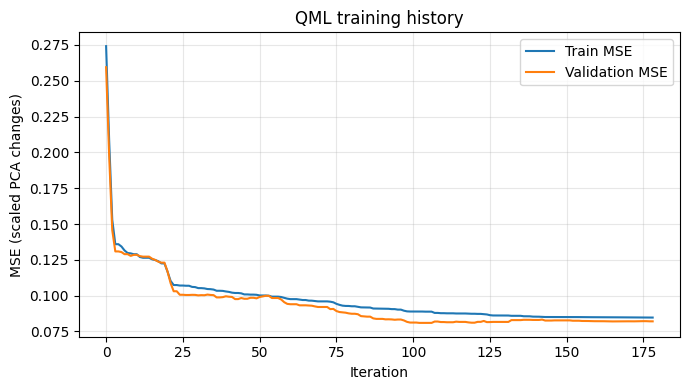

In [28]:
def quantum_loss(theta, X, y):
    prediction = quantum_predict(X, theta)
    return float(np.mean((prediction - y) ** 2))

qml_train_history = []
qml_val_history = []
qml_theta_history = []

iteration = 0

def callback(theta):
    global iteration
    iteration += 1

    train_loss = quantum_loss(theta, X_fit_s, y_fit_s)
    val_loss = quantum_loss(theta, X_val_s, y_val_s)

    qml_train_history.append(train_loss)
    qml_val_history.append(val_loss)
    qml_theta_history.append(theta.copy())

    print(
        f"Iteration {iteration:3d} | "
        f"Train MSE: {train_loss:.6f} | "
        f"Val MSE: {val_loss:.6f}"
    )

rng_qml = np.random.default_rng(seed)
theta0 = rng_qml.uniform(-0.1, 0.1, size=n_params)
initial_train_mse = quantum_loss(theta0, X_fit_s, y_fit_s)

max_qml_iterations = 300
opt = minimize(
    lambda theta: quantum_loss(theta, X_fit_s, y_fit_s),
    theta0,
    method="COBYLA",
    callback=callback,
    options={"maxiter": max_qml_iterations, "rhobeg": 0.2},
)

best_iter = int(np.argmin(qml_val_history))
theta_best = qml_theta_history[best_iter]

final_train_mse = quantum_loss(theta_best, X_fit_s, y_fit_s)
val_qml_mse = quantum_loss(theta_best, X_val_s, y_val_s)

print("Initial train MSE:", round(initial_train_mse, 6))
print("Final train MSE  :", round(final_train_mse, 6))
print("Validation MSE   :", round(val_qml_mse, 6))
print("Optimizer success:", opt.success)
print("Optimizer message:", opt.message)

plt.figure(figsize=(7, 4))

plt.plot(qml_train_history, label="Train MSE")
plt.plot(qml_val_history, label="Validation MSE")
plt.xlabel("Iteration")
plt.ylabel("MSE (scaled PCA changes)")
plt.title("QML training history")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 9. Train the classical MLP benchmark

In [29]:
class SwaptionMLP(nn.Module):
    def __init__(self, input_size=n_components, output_size=n_components):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 32),
            nn.ReLU(),
            nn.Linear(32, output_size),
        )

    def forward(self, x):
        return self.network(x)

model = SwaptionMLP().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

X_fit_tensor = torch.tensor(X_fit_s, dtype=torch.float32, device=device)
y_fit_tensor = torch.tensor(y_fit_s, dtype=torch.float32, device=device)
X_val_tensor = torch.tensor(X_val_s, dtype=torch.float32, device=device)
y_val_tensor = torch.tensor(y_val_s, dtype=torch.float32, device=device)

MLP early stopping at epoch 153.
MLP best validation MSE: 0.070756 (epoch 103)


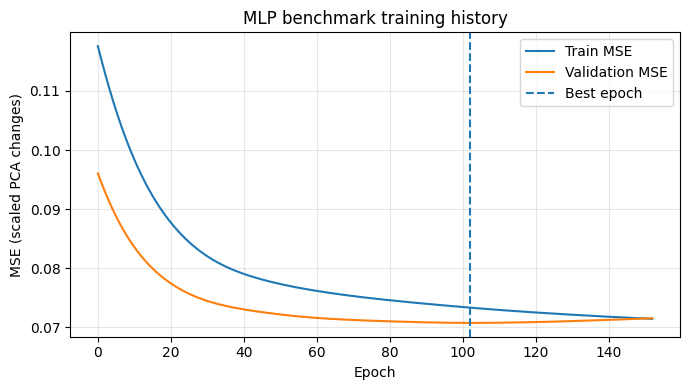

In [30]:
max_epochs = 1500
patience = 50

best_val_loss = float("inf")
best_state = None
wait = 0
train_history = []
val_history = []

for epoch in range(max_epochs):
    model.train()
    optimizer.zero_grad()

    train_pred = model(X_fit_tensor)
    train_loss = loss_fn(train_pred, y_fit_tensor)
    train_loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(X_val_tensor), y_val_tensor).item()

    train_history.append(train_loss.item())
    val_history.append(val_loss)

    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        print(f"MLP early stopping at epoch {epoch + 1}.")
        break

model.load_state_dict(best_state)
model.eval()
print(f"MLP best validation MSE: {best_val_loss:.6f} (epoch {best_epoch})")

plt.figure(figsize=(7, 4))
plt.plot(train_history, label="Train MSE")
plt.plot(val_history, label="Validation MSE")
plt.axvline(best_epoch - 1, linestyle="--", label="Best epoch")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled PCA changes)")
plt.title("MLP benchmark training history")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 10. Compare on the held-out test period

Both models predict changes in PCA coordinates. These changes are converted back to PCA levels and reconstructed into the original surface space. Persistence uses the last observed surface directly. MAE and RMSE are calculated on the same test dates, in original price units.

In [31]:
def reconstruct_surface(z):
    scaled_surface = pca.inverse_transform(z)
    return surface_scaler.inverse_transform(scaled_surface)


def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    }


z_prev_test = np.vstack([val_z[-1:], test_z[:-1]])
y_true = test_df.to_numpy()

# MLP prediction.
with torch.no_grad():
    mlp_delta_s = model(
        torch.tensor(X_test_s, dtype=torch.float32, device=device)
    ).cpu().numpy()
mlp_delta = mlp_delta_s * y_scale
mlp_pred = reconstruct_surface(z_prev_test + mlp_delta)

# Quantum prediction.
qml_delta_s = quantum_predict(X_test_s, theta_best)
qml_delta = qml_delta_s * y_scale
qml_pred = reconstruct_surface(z_prev_test + qml_delta)

# Exact persistence baseline: tomorrow equals today's observed surface.
persistence_pred = np.vstack([val_df.to_numpy()[-1:], test_df.to_numpy()[:-1]])

results = pd.DataFrame({
    "MLP": calculate_metrics(y_true, mlp_pred),
    "QML": calculate_metrics(y_true, qml_pred),
    "Persistence": calculate_metrics(y_true, persistence_pred),
}).T

persistence_rmse = results.loc["Persistence", "RMSE"]
results["RMSE improvement vs persistence (%)"] = (
    (persistence_rmse - results["RMSE"]) / persistence_rmse * 100
)
results.round(6)

,MAE,RMSE,RMSE improvement vs persistence (%)
MLP,0.002975,0.003959,-1.149198
QML,0.003070,0.004099,-4.707011
Persistence,0.002946,0.003914,0.000000


## 11. Visual comparison

The first figure compares test-set MAE/RMSE.
Then predictions on the first, middle and last columns over the last 150 test dates.

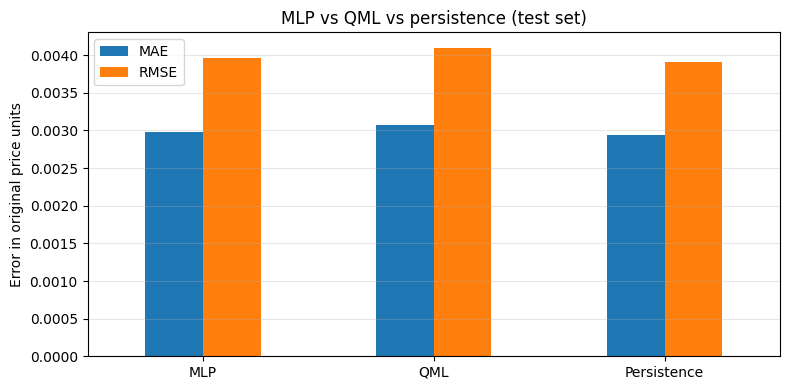

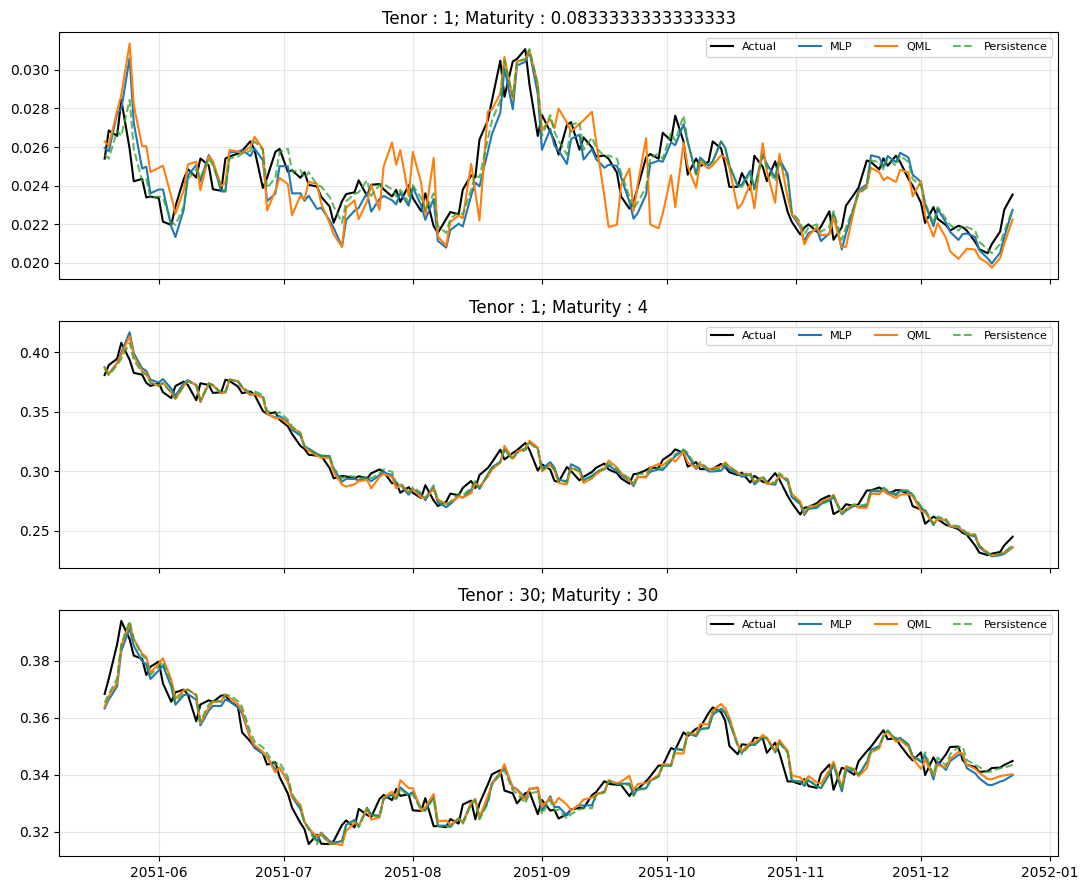

MLP RMSE improvement vs persistence: -1.15%
QML RMSE improvement vs persistence: -4.71%


In [32]:
ax = results[["MAE", "RMSE"]].plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylabel("Error in original price units")
ax.set_title("MLP vs QML vs persistence (test set)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

columns = list(test_df.columns)
picked = sorted(set([0, len(columns) // 2, len(columns) - 1]))
fig, axes = plt.subplots(len(picked), 1, figsize=(11, 3 * len(picked)), sharex=True)
if len(picked) == 1:
    axes = [axes]

for ax, j in zip(axes, picked):
    ax.plot(test_df.index[-150:], y_true[-150:, j], label="Actual", color="black")
    ax.plot(test_df.index[-150:], mlp_pred[-150:, j], label="MLP")
    ax.plot(test_df.index[-150:], qml_pred[-150:, j], label="QML")
    ax.plot(test_df.index[-150:], persistence_pred[-150:, j], label="Persistence", linestyle="--", alpha=0.75)
    ax.set_title(str(columns[j]))
    ax.grid(alpha=0.3)
    ax.legend(ncol=4, fontsize=8)

#axes[0].legend(ncol=4)
plt.tight_layout()
plt.show()

for model_name in ["MLP", "QML"]:
    gain = float(results.loc[model_name, "RMSE improvement vs persistence (%)"])
    print(f"{model_name} RMSE improvement vs persistence: {gain:+.2f}%")

## 12. Conclusion

On the test set, neither model beats persistence (RMSE 0.003914). The MLP is 1.15% worse (0.003959) and the circuit 4.71% worse (0.004099).

- The MLP is better than the circuit, but it does about as well as "nothing changes".
- I also tried re-encoding the inputs at every layer (`reupload = True`): no improvement.
- The circuit has 24 parameters against 292 for the MLP, and it is simulated on a classical machine. Nothing here shows a quantum advantage.
- Limits: one seed, one split, and both models only see 500 of the 3499 training pairs.